Loading ResNet50 on cuda...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]


✅ FastAPI Server Ready on port 8011!
📤 Please upload an image:


Saving wp3971039.png to wp3971039.png


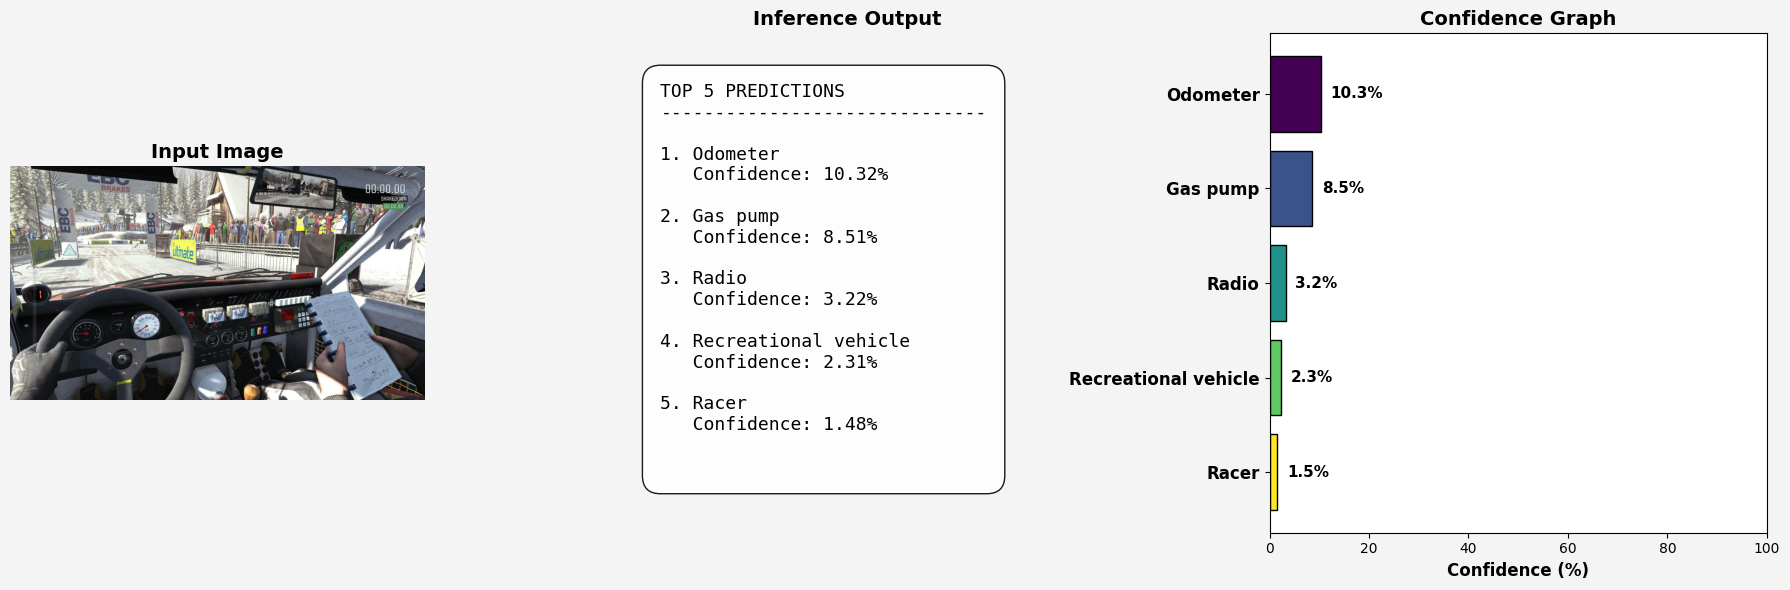

In [ ]:


import os, time, io, threading, asyncio, json
import numpy as np
import requests
from PIL import Image
import matplotlib.pyplot as plt
from fastapi import FastAPI, UploadFile, File
from fastapi.responses import JSONResponse
import uvicorn

# 1. Install if needed
try:
    import torch, torchvision
except ImportError:
    !pip install -q fastapi uvicorn requests pillow matplotlib torch torchvision
    import torch, torchvision

# 2. Load REAL model (ResNet50)
import torch
import torchvision.models as models
import torchvision.transforms as transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading ResNet50 on {device}...")
real_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT).to(device).eval()

# Download ImageNet labels
import urllib.request
if not os.path.exists("imagenet_classes.json"):
    url = "https://raw.githubusercontent.com/raghakot/keras-vis/master/resources/imagenet_class_index.json"
    urllib.request.urlretrieve(url, "imagenet_classes.json")
with open("imagenet_classes.json", "r") as f:
    class_idx = json.load(f)
labels = {int(k): v[1].replace("_", " ") for k, v in class_idx.items()}

# 3. FastAPI app
app = FastAPI()

def preprocess(image_bytes):
    img = Image.open(io.BytesIO(image_bytes)).convert("RGB").resize((224, 224))
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    return transform(img).unsqueeze(0)

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    try:
        raw = await file.read()
        tensor = preprocess(raw).to(device)

        with torch.no_grad():
            logits = real_model(tensor)
            probs = torch.nn.functional.softmax(logits, dim=1)[0]

        top5_prob, top5_idx = torch.topk(probs, 5)
        results = [{
            "class_id": top5_idx[i].item(),
            "class_name": labels.get(top5_idx[i].item(), f"Class {top5_idx[i].item()}"),
            "confidence": top5_prob[i].item()
        } for i in range(5)]

        return JSONResponse({"status": "success", "top5": results})
    except Exception as e:
        return JSONResponse(status_code=500,
                            content={"status": "error", "message": str(e)})

@app.get("/health")
def health(): return {"status": "ok"}

# 4. Start server on FRESH port 8011
PORT = 8011

def _serve():
    cfg = uvicorn.Config(app, host="127.0.0.1", port=PORT, log_level="warning")
    srv = uvicorn.Server(cfg)
    loop = asyncio.new_event_loop()
    asyncio.set_event_loop(loop)
    loop.run_until_complete(srv.serve())

threading.Thread(target=_serve, daemon=True).start()

for i in range(20):
    try:
        if requests.get(f"http://127.0.0.1:{PORT}/health", timeout=1).status_code == 200:
            print(f"✅ FastAPI Server Ready on port {PORT}!")
            break
    except:
        time.sleep(1)
else:
    raise RuntimeError(f"FastAPI did not start on port {PORT}.")

# 5. Upload image
from google.colab import files
print("📤 Please upload an image:")
up = files.upload()
fname = next(iter(up))
img_bytes = up[fname]
img = Image.open(io.BytesIO(img_bytes))

# 6. Send to FastAPI
r = requests.post(f"http://127.0.0.1:{PORT}/predict",
                  files={"file": (fname, img_bytes, "image/jpeg")},
                  timeout=60)
res = r.json()

# 7. Display Image, Text, and Graph
if res.get("status") == "success" and "top5" in res:
    # Extract data for plotting
    names = [item['class_name'].capitalize() for item in res["top5"]]
    confidences = [item['confidence'] * 100 for item in res["top5"]]

    # Create a 3-panel layout: Image | Text | Graph
    fig = plt.figure(figsize=(18, 6))
    fig.patch.set_facecolor('#f4f4f4')
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])

    # --- Panel 1: Input Image ---
    ax1 = fig.add_subplot(gs[0])
    ax1.imshow(img)
    ax1.set_title("Input Image", fontsize=14, fontweight='bold')
    ax1.axis("off")

    # --- Panel 2: Text Output ---
    ax2 = fig.add_subplot(gs[1])
    ax2.axis("off")
    text = "TOP 5 PREDICTIONS\n" + "-"*30 + "\n\n"
    for i, item in enumerate(res["top5"]):
        text += f"{i+1}. {item['class_name'].capitalize()}\n"
        text += f"   Confidence: {item['confidence']:.2%}\n\n"

    ax2.text(0.05, 0.9, text, fontsize=13, va="top", family="monospace",
             transform=ax2.transAxes,
             bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=1'))
    ax2.set_title("Inference Output", fontsize=14, fontweight='bold')

    # --- Panel 3: Bar Graph ---
    ax3 = fig.add_subplot(gs[2])
    # Reverse order so the highest probability is at the top of the graph
    y_pos = np.arange(len(names))
    colors = plt.cm.viridis(np.linspace(0, 1, len(names)))[::-1]

    bars = ax3.barh(y_pos, confidences[::-1], color=colors, edgecolor='black')
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels(names[::-1], fontsize=12, fontweight='bold')
    ax3.set_xlabel("Confidence (%)", fontsize=12, fontweight='bold')
    ax3.set_title("Confidence Graph", fontsize=14, fontweight='bold')
    ax3.set_xlim(0, 100) # Fix x-axis from 0 to 100%

    # Add percentage text to the end of each bar
    for bar in bars:
        width = bar.get_width()
        ax3.text(width + 2, bar.get_y() + bar.get_height()/2,
                 f'{width:.1f}%', va='center', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()

else:
    print("❌ Error:", res.get("message", "Unknown error"))